In [ ]:
import sys
sys.path.insert(0, "..")   # repo root, so the systems/ and lib/ packages import
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp
from systems.three_body.state import State
from systems.three_body.states import figure_eight


In [ ]:
def rhs(t, y):
    return State(y).derivative()


system_path = solve_ivp(rhs, (0,50), y0 = figure_eight.y, method = "DOP853", rtol=1e-10, atol=1e-12)

plt.plot(system_path.y[0],system_path.y[1])
plt.plot(system_path.y[4],system_path.y[5])
plt.plot(system_path.y[8],system_path.y[9])

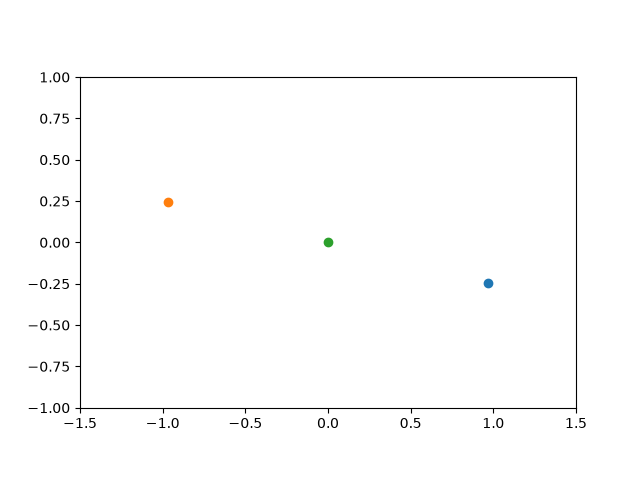

In [18]:
from matplotlib.animation import FuncAnimation
from IPython.display import Image

# resample the solver's uneven steps onto evenly spaced frame times
t = np.linspace(system_path.t[0], system_path.t[-1], 500)
p = np.array([np.interp(t, system_path.t, row) for row in system_path.y]).reshape(3, 4, -1)  # [body, (x, y, vx, vy), time]

fig, ax = plt.subplots()
ax.set_aspect("equal"); ax.set_xlim(-1.5, 1.5); ax.set_ylim(-1, 1)
paths = [ax.plot([], [], color=f"C{b}")[0] for b in range(3)]
dots = [ax.plot([], [], "o", color=f"C{b}")[0] for b in range(3)]

def update(k):
    s = slice(max(0, k-10), k+1)
    for b in range(3):
        paths[b].set_data(p[b, 0, s], p[b, 1, s])
        dots[b].set_data([p[b, 0, k]], [p[b, 1, k]])
    return paths + dots

FuncAnimation(fig, update, frames=len(t), interval=33, blit=True).save("fig8.gif", writer="pillow", fps=30)
plt.close(fig)
Image("fig8.gif")